In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import os
import numpy as np

saving_folders = ['l0','l1','l2','l3','l4','l5','l6','l7','l8','l9']
work_folder = 'edge_spen'

init = 0
fin = 1999
results_list = []
actor_weight_list = []
critic_weight_list = []

main_folder = os.getcwd()

for saving_folder in saving_folders:
    results_folder = os.path.join(work_folder, saving_folder, 'results')
    
    file_path = os.path.join(results_folder, 'results.txt')
    
    with open(file_path, 'r') as f:
        res = [line.split() for line in f if line.strip()]  
    
    res = np.array(res, dtype=float)
    
    res = res[init:fin]
    #assert res.shape[1] == 5, f"{saving_folder} ha {res.shape[1]} colonne invece di 5"
    
    results_list.append(res)
    
    actor_file_path = os.path.join(results_folder, 'actor_weights.txt')  
    critic_file_path = os.path.join(results_folder, 'critic_weights.txt')
    
    with open(critic_file_path, 'r') as f:
        c_weights = f.readlines()

    with open(actor_file_path, 'r') as f:
        a_weights = f.readlines()

    cw = [eval(line) for line in c_weights]
    aw = [eval(line) for line in a_weights]

    cwt = np.array(cw, dtype=float)[init:fin]
    awt = np.array(aw, dtype=float)[init:fin]
    
    actor_weight_list.append(awt)
    critic_weight_list.append(cwt)
    

# ora puoi impilare senza problemi
results = np.stack(results_list)  # crea array 3D
actor_array = np.stack(actor_weight_list)
critic_array = np.stack(critic_weight_list)

print(results.shape)

(10, 1999, 5)


/tmp/ipykernel_6956/3171557086.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('YlGnBu')
/tmp/ipykernel_6956/3171557086.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap1 = cm.get_cmap('YlOrRd')


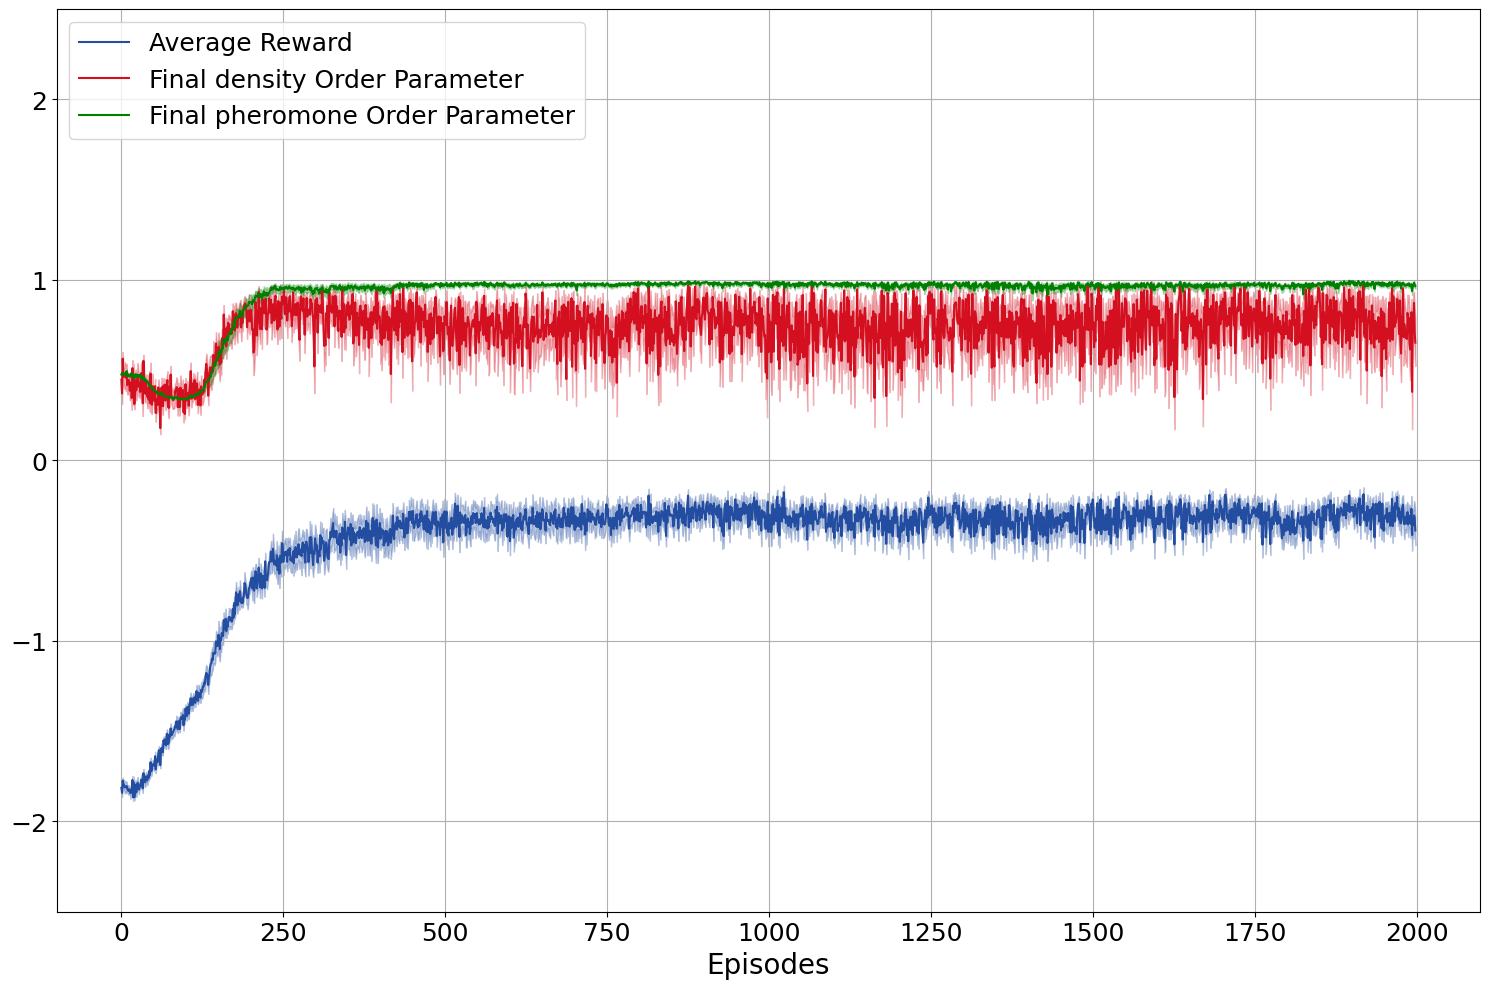

In [3]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# results shape: (num_folders, num_episodes, num_features)
num_folders = results.shape[0]

mean_results = np.mean(results, axis=0)        # shape: (num_episodes, num_features)
std_error = np.std(results, axis=0, ddof=1) / np.sqrt(num_folders)

cmap = cm.get_cmap('YlGnBu')
cmap1 = cm.get_cmap('YlOrRd')

rew_color = cmap(0.8)
op_color = cmap1(0.8)
pher_color = 'green'

fig, ax1 = plt.subplots(figsize=(15,10))

# Average Reward with standard err
ax1.plot(mean_results[:,1], label='Average Reward', c=rew_color)
ax1.fill_between(np.arange(mean_results.shape[0]),
                 mean_results[:,1] - std_error[:,1],
                 mean_results[:,1] + std_error[:,1],
                 color=rew_color, alpha=0.3)

# Order Parameters
ax1.plot(mean_results[:,3], label='Final density Order Parameter', c=op_color)
ax1.fill_between(np.arange(mean_results.shape[0]),
                 mean_results[:,3] - std_error[:,3],
                 mean_results[:,3] + std_error[:,3],
                 color=op_color, alpha=0.3)

ax1.plot(mean_results[:,4], label='Final pheromone Order Parameter', c=pher_color)
ax1.fill_between(np.arange(mean_results.shape[0]),
                 mean_results[:,4] - std_error[:,4],
                 mean_results[:,4] + std_error[:,4],
                 color=pher_color, alpha=0.3)

# Font control (KEY PART)
ax1.tick_params(axis='both', which='major', labelsize=18)
ax1.set_xlabel('Episodes', fontsize=20)
ax1.legend(loc='upper left', fontsize=18)
ax1.grid()
ax1.set_ylim(-2.5, 2.5)

plt.tight_layout()
plt.show()


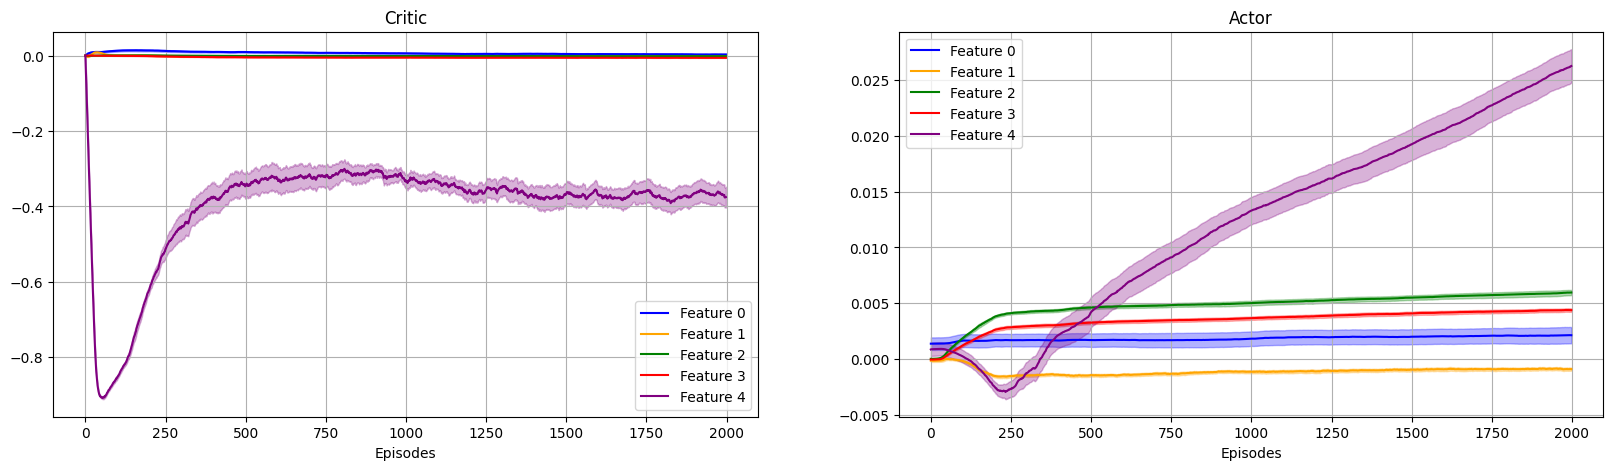

In [4]:
# actor_array e critic_array hanno shape (num_files, num_episodes, num_features)

def plot_weights_with_error(weights_array, title, ax, colors=None):
    mean_weights = np.mean(weights_array, axis=0)       # media su file/layers
    std_error = np.std(weights_array, axis=0, ddof=1) / np.sqrt(weights_array.shape[0])
    
    num_features = mean_weights.shape[1]
    x = np.arange(mean_weights.shape[0])
    
    for i in range(num_features):
        color = colors[i] if colors is not None else None
        ax.plot(x, mean_weights[:,i], label=f'Feature {i}', color=color)
        ax.fill_between(x,
                        mean_weights[:,i] - std_error[:,i],
                        mean_weights[:,i] + std_error[:,i],
                        alpha=0.3, color=color)
    
    ax.set_title(title)
    ax.set_xlabel('Episodes')
    ax.legend()
    ax.grid(True)

fig, ax = plt.subplots(1, 2, figsize=(20,5))

colors = ['blue', 'orange', 'green', 'red', 'purple']

plot_weights_with_error(critic_array, 'Critic', ax[0], colors)
plot_weights_with_error(actor_array, 'Actor', ax[1], colors)

plt.show()

In [5]:
updates = 1000
geometric_progression = np.unique(np.logspace(0, np.log10(198), num=10, dtype=int))
test_res = []
for saving_folder in saving_folders:
    results_folder = os.path.join(work_folder, saving_folder, 'results_test')
    reward_file = os.path.join(results_folder, 'reward.txt')

    with open(reward_file, 'r') as f:
        op = f.readlines()
    
    # Process data
    op = [line.split() for line in op]
    op = np.array(op, dtype=float)
    op = op.reshape(len(op)//updates, updates)
    op = op[geometric_progression]

    test_res.append(op)

In [6]:
geometric_progression

array([  1,   3,   5,  10,  18,  33,  61, 110, 197])

In [7]:
test_res = np.array(test_res)    

/tmp/ipykernel_6956/1904381961.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap(colormap)(np.linspace(0, 1, len(op)))


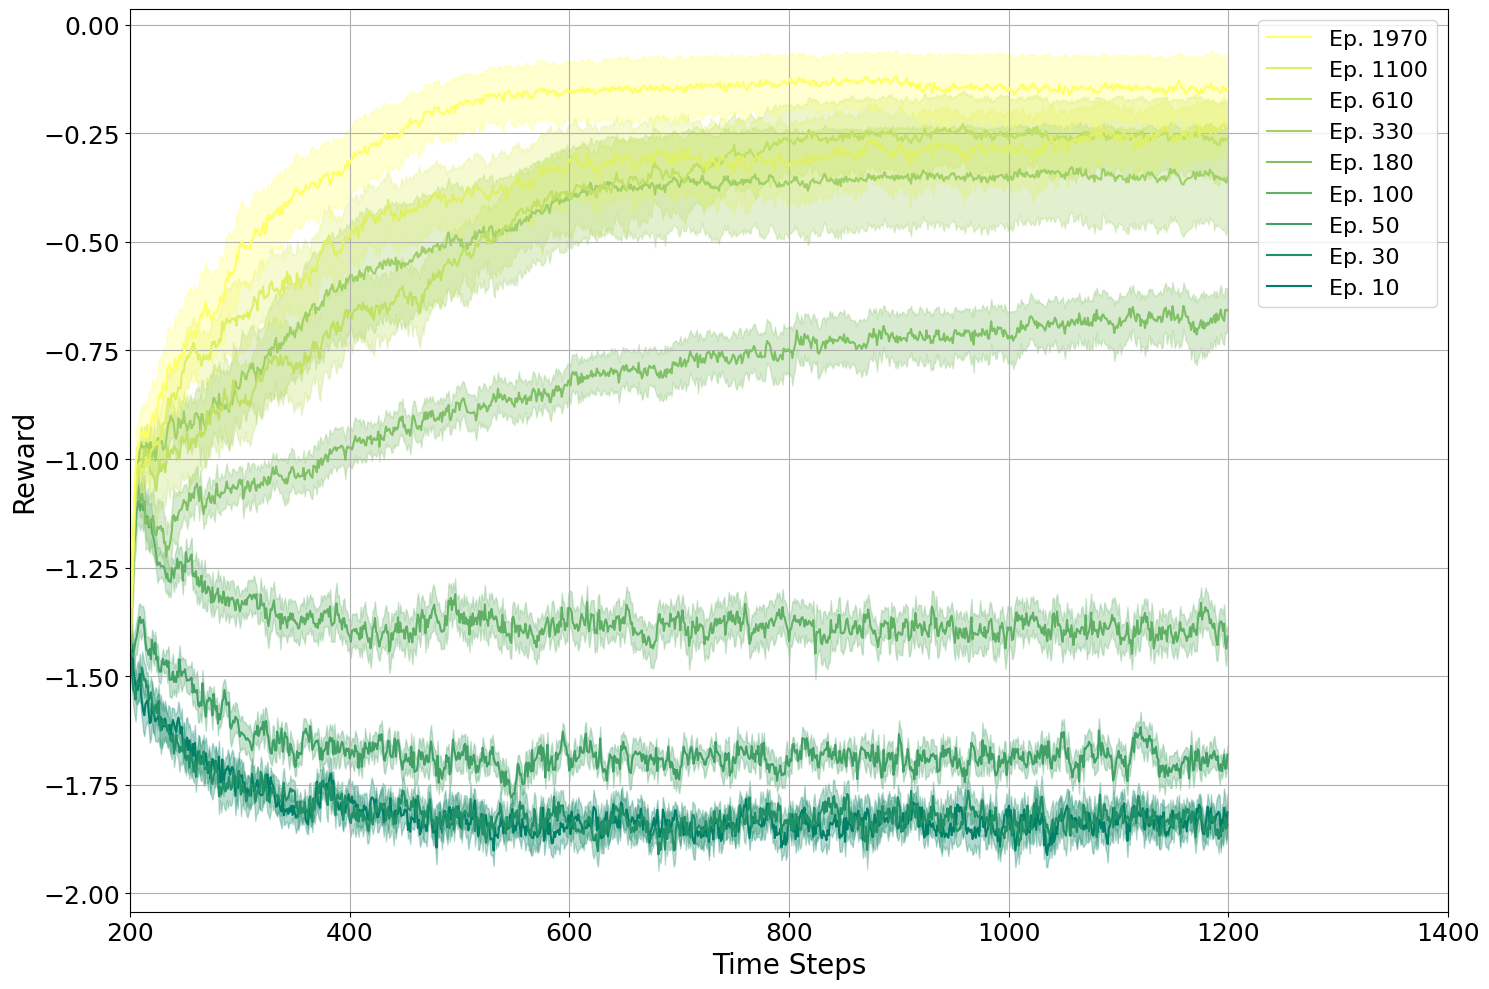

In [8]:
colormap = 'summer'
colors = plt.cm.get_cmap(colormap)(np.linspace(0, 1, len(op)))

plt.figure(figsize=(15,10))

mean_test_res = np.mean(test_res, axis=0)
std_error_test = np.std(test_res, axis=0, ddof=1) / np.sqrt(len(saving_folders))

for i in range(mean_test_res.shape[0]):
    plt.plot(mean_test_res[i],
             label=f'Ep. {(geometric_progression[i])*10}',
             color=colors[i])
    plt.fill_between(np.arange(mean_test_res[i].shape[0]),
                     mean_test_res[i] - std_error_test[i],
                     mean_test_res[i] + std_error_test[i],
                     color=colors[i], alpha=0.3)

# Font control ONLY
plt.tick_params(axis='both', which='major', labelsize=18)
plt.xlabel('Time Steps', fontsize=20)
plt.ylabel('Reward', fontsize=20)

# Reverse legend order
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[::-1], labels[::-1], loc='upper right', fontsize=16)

plt.grid()
plt.xlim(0, updates+100)
ax = plt.gca()

ticks = ax.get_xticks()
ax.set_xticks(ticks)
ax.set_xticklabels((ticks + 200).astype(int))

plt.tight_layout()
plt.show()
